## Learning objectives
1. Inspect and clean the Auto MPG dataset.
2. Handle missing horsepower values and encode the categorical `Origin` feature.
3. Split the data into training, validation, and test sets.
4. Standardize features without data leakage.
5. Build and train a feed-forward neural network in PyTorch.
6. Plot training/validation loss and MAE, evaluate test performance, and inspect predictions.

**Dataset requirement:** Place `auto-mpg.csv` in the same folder as this notebook. The file should contain columns such as `MPG`, `Cylinders`, `Displacement`, `Horsepower`, `Weight`, `Acceleration`, `Model Year`, `Origin`, and optionally `Car name`.

The notebook uses a validation set separate from the test set. The scaler is fitted only on training features to avoid data leakage.

## Import lib

In [202]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch import nn
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

In [203]:
# Make the experiment more repeatable
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

In [204]:
# use the GPU when available other  run on cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Pytorch  version ",torch.__version__)
print("Training device",device)

Pytorch  version  2.11.0+cu130
Training device cuda


### Load the data

In [205]:
csv_path ="/content/drive/MyDrive/Edgeverve datasets/auto-mpg.csv"
if not os.path.exists(csv_path):
  raise FileNotFoundError(
      "Could not find the auto-mpg.csv . Please check the path of csv file."
  )

df_auto= pd.read_csv(csv_path)
print("Dataset sharpe ",df_auto.shape)
display(df_auto.head())


Dataset sharpe  (398, 9)


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin,Car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [206]:
# count the missing value in each column
print("Missing values before cleaning ")
display(df_auto.isna().sum().to_frame("missing_count"))

Missing values before cleaning 


,missing_count
MPG,0
Cylinders,0
Displacement,0
Horsepower,0
Weight,0
Acceleration,0
Model year,0
Origin,0
Car name,0


In [207]:
# remove the car name because it is a free text indentifier , not the numeric predicatior
if "Car name" in df_auto.columns:
  df_auto = df_auto.drop(columns=["Car name"])

In [208]:
display(df_auto.head())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1


In [209]:
df_auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MPG           398 non-null    float64
 1   Cylinders     398 non-null    int64  
 2   Displacement  398 non-null    float64
 3   Horsepower    398 non-null    object 
 4   Weight        398 non-null    int64  
 5   Acceleration  398 non-null    float64
 6   Model year    398 non-null    int64  
 7   Origin        398 non-null    int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 25.0+ KB


In [210]:
df_auto["Horsepower"].nunique()

94

In [211]:
df_auto["Horsepower"].unique()

array(['130', '165', '150', '140', '198', '220', '215', '225', '190',
       '170', '160', '95', '97', '85', '88', '46', '87', '90', '113',
       '200', '210', '193', '?', '100', '105', '175', '153', '180', '110',
       '72', '86', '70', '76', '65', '69', '60', '80', '54', '208', '155',
       '112', '92', '145', '137', '158', '167', '94', '107', '230', '49',
       '75', '91', '122', '67', '83', '78', '52', '61', '93', '148',
       '129', '96', '71', '98', '115', '53', '81', '79', '120', '152',
       '102', '108', '68', '58', '149', '89', '63', '48', '66', '139',
       '103', '125', '133', '138', '135', '142', '77', '62', '132', '84',
       '64', '74', '116', '82'], dtype=object)

In [212]:
# tring accedental whitespace
df_auto.columns = [column.strip()  for column in df_auto.columns]
if "Horsepower" not in  df_auto.columns:
  raise KeyError("Expected a Horsepower columns . Check dataset column names")

In [213]:
# missing horce power values are represented by ?
df_auto = df_auto.replace("?",np.nan)

In [214]:
# convert numeric columns from strings to numbers . Invalid values become NaN
for column in df_auto.columns:
  if column != "Origin":
    df_auto[column] = pd.to_numeric(df_auto[column],errors="coerce")

In [215]:
print("Data type after conversion")
display(df_auto.dtypes.to_frame('dtype'))

Data type after conversion


,dtype
MPG,float64
Cylinders,int64
Displacement,float64
Horsepower,float64
Weight,int64
Acceleration,float64
Model year,int64
Origin,int64


In [216]:
# missing value after conversion
display(df_auto.isna().sum().to_frame("missing_count"))


,missing_count
MPG,0
Cylinders,0
Displacement,0
Horsepower,6
Weight,0
Acceleration,0
Model year,0
Origin,0


### Explore data

In [217]:
display(df_auto.describe().T)

,count,mean,std,min,25%,50%,75%,max
MPG,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
Cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
Displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
Horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
Weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
Acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
Model year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0
Origin,398.0,1.572864,0.802055,1.0,1.000,1.0,2.000,3.0


In [218]:
display(df_auto[df_auto["Horsepower"].isna()].head())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin
32,25.0,4,98.0,NaN,2046,19.0,71,1
126,21.0,6,200.0,NaN,2875,17.0,74,1
330,40.9,4,85.0,NaN,1835,17.3,80,2
336,23.6,4,140.0,NaN,2905,14.3,80,1
354,34.5,4,100.0,NaN,2320,15.8,81,2


In [219]:
# fill missing numeric values with the median of each numeric columns
numeric_columns = df_auto.select_dtypes(include=[np.number]).columns
for column  in  numeric_columns:
  df_auto[column] = df_auto[column].fillna(df_auto[column].median())

In [220]:
display(df_auto[df_auto["Horsepower"].isna()].head())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin


In [221]:
df_auto['Origin'].nunique()

3

In [222]:
df_auto['Origin'].unique()

array([1, 3, 2])

In [223]:
# If origin is stored as 1 , 2 or 3 map it to readable category names.
# if it already text leave as it is
if 'Origin'  in df_auto.columns:
  origin_map = {1:"USA",2:"Europe",3:"Japan"}
  df_auto['Origin']= df_auto['Origin'].map(lambda value : origin_map.get(value,value))

In [224]:
display(df_auto.head())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin
0,18.0,8,307.0,130.0,3504,12.0,70,USA
1,15.0,8,350.0,165.0,3693,11.5,70,USA
2,18.0,8,318.0,150.0,3436,11.0,70,USA
3,16.0,8,304.0,150.0,3433,12.0,70,USA
4,17.0,8,302.0,140.0,3449,10.5,70,USA


### Visualize relationship between variable


Text(0.5, 0.98, 'Auto MPG : Pairwise relationships ')

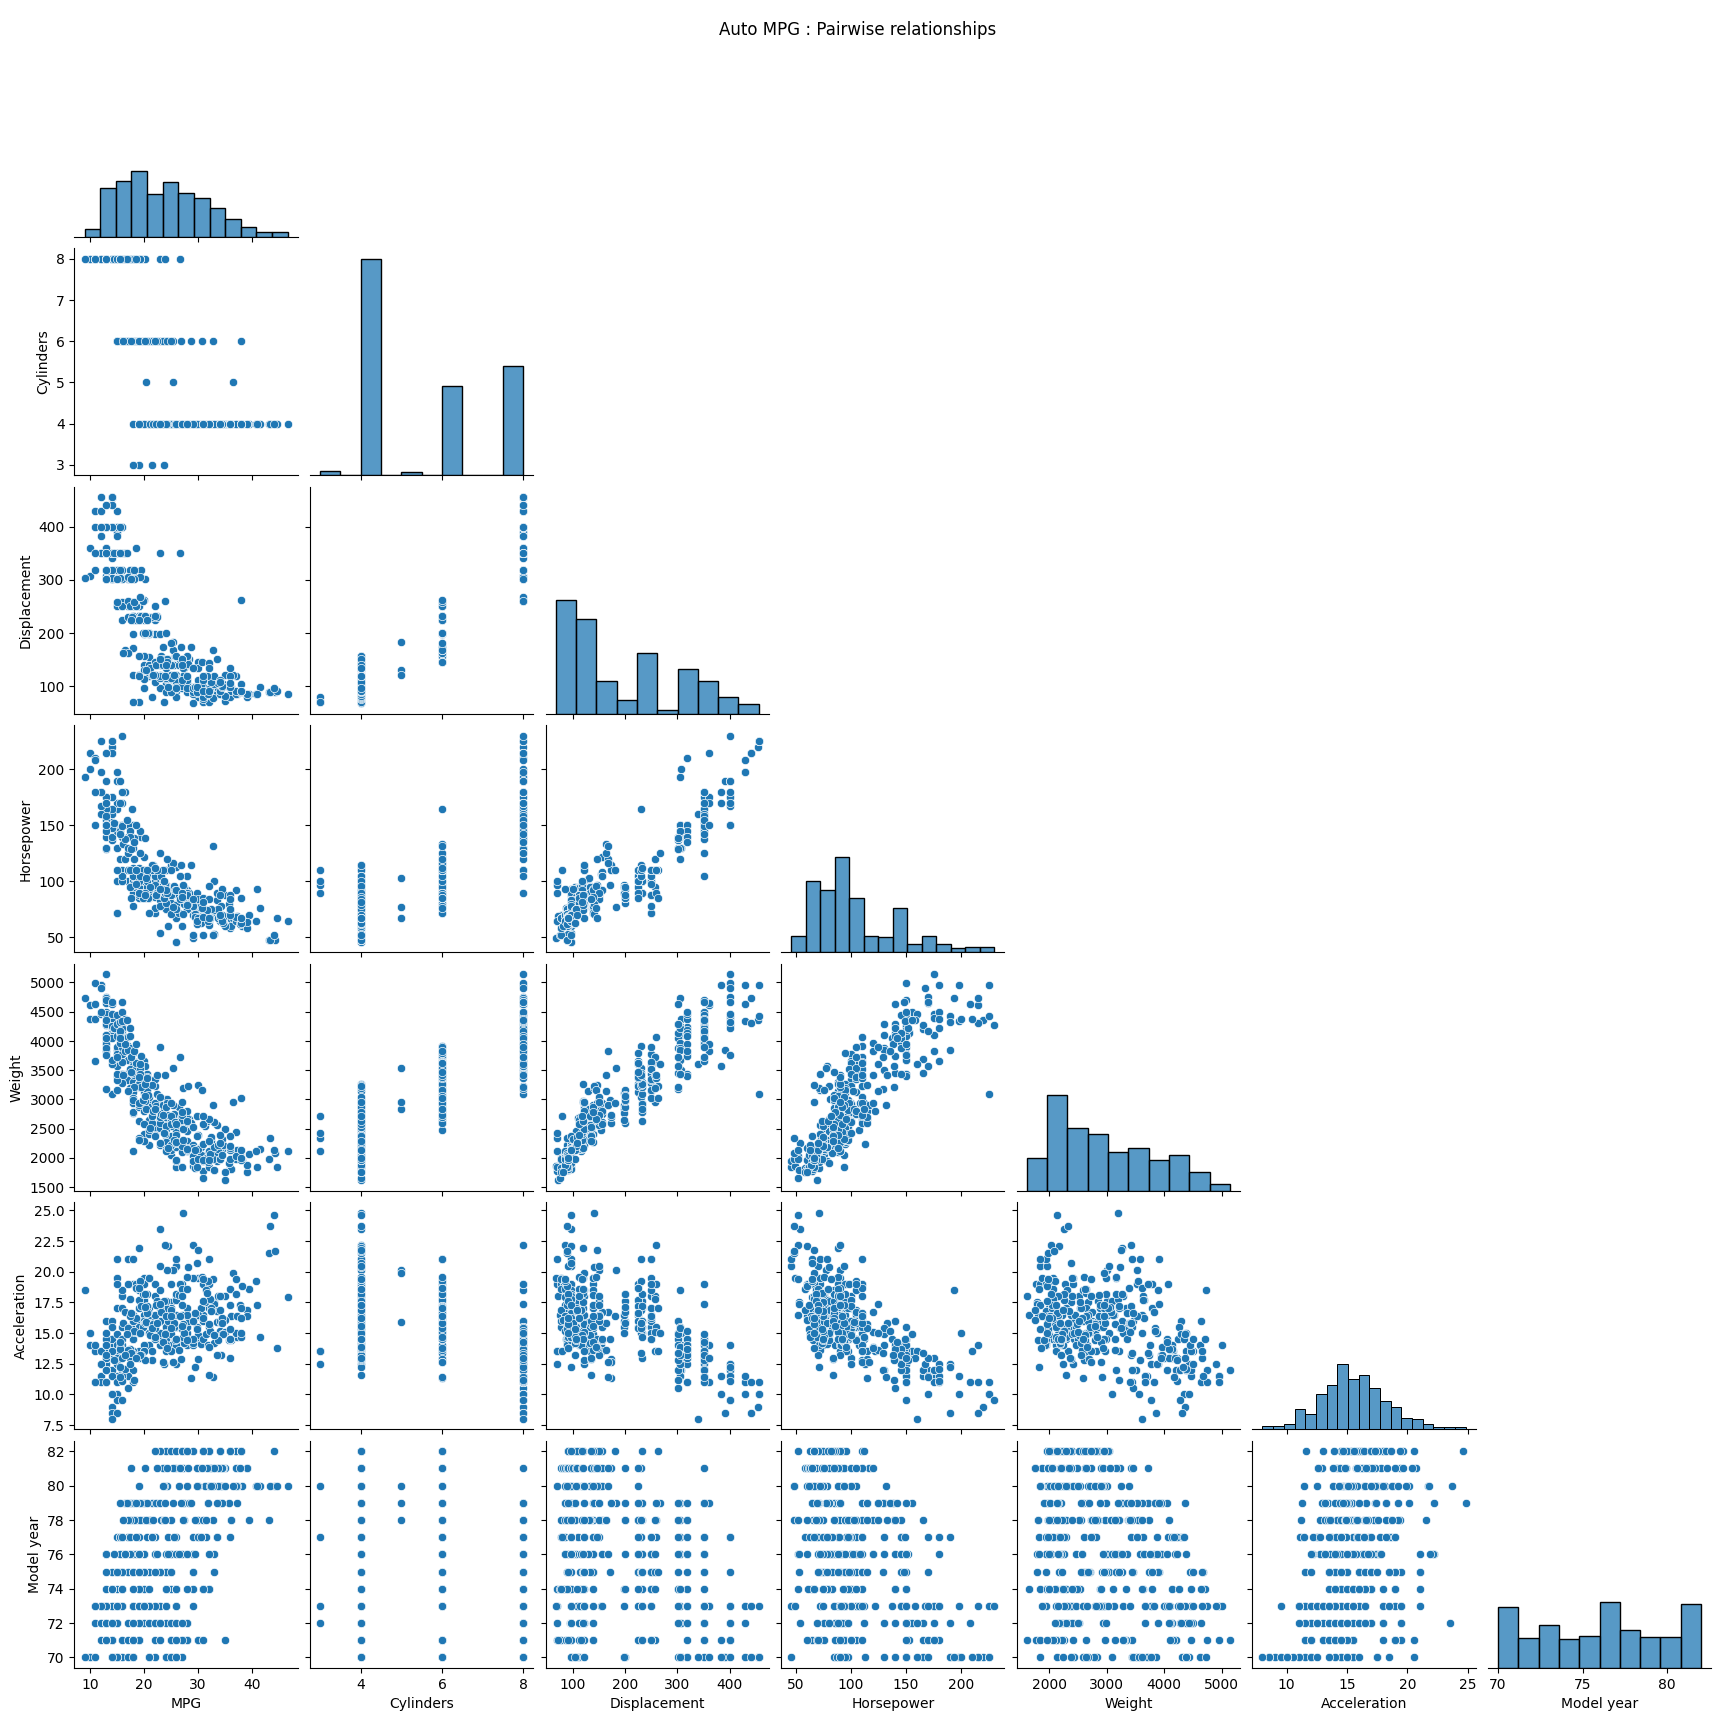

In [225]:
sns.pairplot(df_auto.select_dtypes(include=[np.number]),corner =True , diag_kind="hist")
plt.suptitle("Auto MPG : Pairwise relationships ")

### Encode the categorical Origin Feature

In [226]:
# one hot encoding avoids trating origin categories as order numeric scale

if 'Origin' in df_auto.columns:
  df_auto = pd.get_dummies(df_auto,columns=['Origin'],dtype=np.float32)

In [227]:
df_auto=df_auto.apply(pd.to_numeric) # ensure all features are numeric and display transformed table
display(df_auto.head())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model year,Origin_Europe,Origin_Japan,Origin_USA
0,18.0,8,307.0,130.0,3504,12.0,70,0.0,0.0,1.0
1,15.0,8,350.0,165.0,3693,11.5,70,0.0,0.0,1.0
2,18.0,8,318.0,150.0,3436,11.0,70,0.0,0.0,1.0
3,16.0,8,304.0,150.0,3433,12.0,70,0.0,0.0,1.0
4,17.0,8,302.0,140.0,3449,10.5,70,0.0,0.0,1.0


# train and test data
   - target MPG

In [228]:
target_column = "MPG"
if target_column not in df_auto.columns:
  raise KeyError("The dataset must contain an MPG target column")
# remove any row with invalida numeric values after preprocessing
df = df_auto.dropna().copy()
X = df.drop(columns=[target_column]).astype(np.float32)
y=df[target_column].astype(np.float32)

# creating test and train data
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.30,random_state=42)

In [229]:
# creating validation and train data
X_train1,X_val,y_train1,y_test1= train_test_split(X_train,y_train,test_size=0.20,random_state=42)

In [230]:
print("X Training data shape ",X_train.shape)
print("Y Training data shape ",y_train.shape)
print("X Test data shape ",X_test.shape)
print("Y Test data shape ",y_test.shape)

X Training data shape  (278, 9)
Y Training data shape  (278,)
X Test data shape  (120, 9)
Y Test data shape  (120,)


In [231]:
print("X Training  Validation data shape ",X_train1.shape)
print("Y Training Validation data shape ",y_train1.shape)
print("X Test validation data shape ",X_val.shape)
print("Y Test validation data shape ",y_test1.shape)

X Training  Validation data shape  (222, 9)
Y Training Validation data shape  (222,)
X Test validation data shape  (56, 9)
Y Test validation data shape  (56,)


Standardize the input features

In [232]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train1).astype(np.float32)
X_val_scaled = scaler.fit_transform(X_val).astype(np.float32)
X_test_scaled = scaler.fit_transform(X_test).astype(np.float32)


In [233]:
# pytorch models work with tensors so convert numpy arrays to float 32 tensor.

In [234]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)

In [235]:
 # Regression targets have shape (N,1) matching the model's single output neuron
y_train_tensor  = torch.tensor(y_train1.to_numpy(),dtype=torch.float32).view(-1,1)  # Returns a new tensor with the same data as the self tensor but of a
#different shape.
y_val_tensor  = torch.tensor(y_test1.to_numpy(),dtype=torch.float32).view(-1,1)
y_test_tensor  = torch.tensor(y_test.to_numpy(),dtype=torch.float32).view(-1,1)

In [236]:
print("X train tensor shape", tuple(X_train_tensor.shape))
print("y train tensor shape", tuple(y_train_tensor.shape))
print("X test tensor shape", tuple(X_test_tensor.shape))
print("y test tensor shape", tuple(y_test_tensor.shape))

X train tensor shape (222, 9)
y train tensor shape (222, 1)
X test tensor shape (120, 9)
y test tensor shape (120, 1)


# Build a feed-forward neural network

In [237]:
class MPGRegressor(nn.Module):
  def __init__(self,input_features):
    super().__init__()
    self.network = nn.Sequential(
        # hidden layer with 20 neuron and Relu non linearity
        nn.Linear(input_features,20),
        nn.ReLU(),
        nn.Linear(20,1)  # output layer  : predicted MPG

    )

  def forward(self,x):
    # the forwatd method defines how input featurs flow through the network
    return self.network(x)




In [238]:
model = MPGRegressor(input_features=X_train_tensor.shape[1]).to(device)
print(model)
# trainable prameters : weights and biases that nn learn during training .  ex :  20 weights and 5 baise =  total trainable prameter = 20 +5 = 25
# model.prameters()  return all parameters(weights and biases) belonging to the model
# p.requires_grad :  checks whether a pramater should receive gradient calculation and be eligible for gradient based updates
#  if it is True : prarameter is trainable by default , if False : the parameter is frozen and does not receive gradient
# p.numel()  returns the total niber of individual values in a  parameter tensor . example :  a weight matrix of (5,3)  contains  5 *3 = 15 values
print("Trainable prarameter :",sum(p.numel() for p in model.parameters() if p.requires_grad))

MPGRegressor(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=20, bias=True)
    (1): ReLU()
    (2): Linear(in_features=20, out_features=1, bias=True)
  )
)
Trainable prarameter : 221


Configure Loss Function And Optimizer

In [239]:
criterion = nn.MSELoss()  # MEAN Square error is common loss function for regression
Learning_Rate=0.01
# Adam adapts parameter updates using gradient information
optimizer = torch.optim.Adam(model.parameters(),lr=Learning_Rate)

Epochs =100
Batch_size =32
print("Loss",criterion)
print("Optimizer ",optimizer.__class__.__name__)
print(f"Learning Rate :  {Learning_Rate}  |  Epochs :  {Epochs} |  Batch Size : {Batch_size}")

Loss MSELoss()
Optimizer  Adam
Learning Rate :  0.01  |  Epochs :  100 |  Batch Size : 32


# Create Dataloader and train the network

In [240]:
from torch.utils.data  import TensorDataset,DataLoader
# TensorDataset() wrap the tensor so each sample is (features , target ) pair
# DataLoader()  it serves that data in mini batch
# shuffle = True  reorders the training data every epochs so the models does not learn the row order
train_loader = DataLoader(TensorDataset(X_train_tensor,y_train_tensor),batch_size=Batch_size,shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor,y_val_tensor),batch_size=Batch_size)



In [241]:
#L1Loss is the MAE mean absolute error . We use only to measure not to train
mae_fn = nn.L1Loss()
history =  {
    "loss" : [] ,
            "mae" :  [] ,
            "val_loss" : [],
            "val_mae": []
    }

In [242]:
print(type(model))
batch_x=X_train_tensor[:4].to(device)
out=model(batch_x)
print(type(out))
print(criterion(out,y_train_tensor[:4].to(device)))

<class '__main__.MPGRegressor'>
<class 'torch.Tensor'>
tensor(1295.6096, device='cuda:0', grad_fn=<MseLossBackward0>)


In [243]:
for epoch in range(Epochs):
  # -----  training phase ----
  model.train()  # training model
  # running totals for this epoch  : sum of MSE , sum of MAE and number of samples

  mse_sum = mae_sum = n =0

  # loop over training data one mini batch at a time
  for x ,y  in train_loader:
    # move the batch to the same device as model (CPU/GPU)
    x,y =  x.to(device) , y.to(device)
    pred  = model(x)  # forward pass :  the model predicts targer for this batch

    loss =criterion(pred,y) # compute loss MSE between predicted and actual

    optimizer.zero_grad() #  clear gradients left over from the previous bach
    # otherwise Pytorch would add them together

    loss.backward()  # backprapogation : compute the gradient of loss
    optimizer.step()  # update the weights using those gradients

    # criteron returns the AVERAGE loss of the batch so  multiple by the
    # batch size to get batch total. This keeps the epoch average correct
    # even  if the last batch smaller than others

    mse_sum += loss.item() * len(y)  # .item() converts the 1-element tensor to a python float
    mae_sum += mae_fn(pred,y).item() * len(y) # same as mse_sum idea
    n+=len(y)

  # divide the total  by number of samples  to get epoch level average
  train_mse , train_mae =  mse_sum/n , mae_sum/n

  model.eval()  #  evaluation mode : disable dropout , freeze norm statistic

  mse_sum = mae_sum = n =0

  # turn off the gradient tracking : we are not training here so this save time and memory
  with torch.no_grad():
    for x,y in val_loader:
      x,y =  x.to(device) , y.to(device)
      pred  = model(x)  #
      loss =criterion(pred,y)
      mse_sum += loss.item() * len(y)  # .item() converts the 1-element tensor to a python float
      mae_sum += mae_fn(pred,y).item() * len(y) # same as mse_sum idea
      n+=len(y)

  val_mse , val_mae =  mse_sum/n , mae_sum/n


  history["loss"].append(train_mse)
  history["mae"].append(train_mae)
  history["val_loss"].append(val_mse)
  history["val_mae"].append(val_mae)


  if(epoch+1) % 5 == 0  or epoch == 0:
    print(f"Epoch {epoch+1}/{Epochs} |  train MSE  {train_mse : .3f} |  MAE  {train_mae : .3f}  |  val mse :  {val_mse:.3f}  |  val MAE {val_mae : .3f} ")












Epoch 1/100 |  train MSE   608.539 |  MAE   23.482  |  val mse :  601.374  |  val MAE  23.203 
Epoch 5/100 |  train MSE   385.934 |  MAE   18.499  |  val mse :  325.689  |  val MAE  16.941 
Epoch 10/100 |  train MSE   55.280 |  MAE   6.116  |  val mse :  36.207  |  val MAE  4.928 
Epoch 15/100 |  train MSE   23.063 |  MAE   3.828  |  val mse :  13.846  |  val MAE  2.836 
Epoch 20/100 |  train MSE   16.596 |  MAE   3.180  |  val mse :  12.552  |  val MAE  2.691 
Epoch 25/100 |  train MSE   13.783 |  MAE   2.855  |  val mse :  11.349  |  val MAE  2.562 
Epoch 30/100 |  train MSE   12.057 |  MAE   2.644  |  val mse :  10.481  |  val MAE  2.465 
Epoch 35/100 |  train MSE   10.963 |  MAE   2.498  |  val mse :  10.116  |  val MAE  2.440 
Epoch 40/100 |  train MSE   10.232 |  MAE   2.385  |  val mse :  9.897  |  val MAE  2.421 
Epoch 45/100 |  train MSE   9.626 |  MAE   2.296  |  val mse :  9.797  |  val MAE  2.411 
Epoch 50/100 |  train MSE   9.192 |  MAE   2.214  |  val mse :  9.418  |  val